<a href="https://colab.research.google.com/github/fddxxueyj/SINDy-ENSO-Recharge-Discharge-Model/blob/main/SINDy_ReDischarge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
!pip install pysindy

In [18]:
import pysindy as ps
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import warnings
import seaborn as sns


from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Read the CSV file
df = pd.read_csv('/content/drive/MyDrive/SINDy_ENSO/ENSO_h_sst_series.csv')

# Extract columns into separate NumPy arrays
time = df['time'].to_numpy()
h = df['h'].to_numpy()
sst = df['sst'].to_numpy()

Mounted at /content/drive


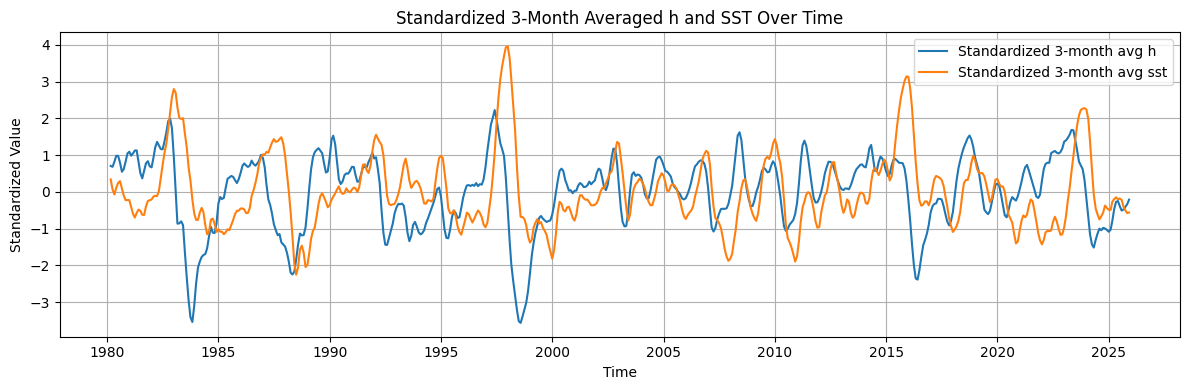

In [19]:
# Convert 'time' to datetime objects for plotting
df['time'] = pd.to_datetime(df['time'])

# Calculate 3-month rolling mean for h and sst
h_rolling_mean = df['h'].rolling(window=3).mean()
sst_rolling_mean = df['sst'].rolling(window=3).mean()

# Standardize the rolling mean series (mean=0, std=1)
# Drop NaN values introduced by rolling mean before standardization
h_standardized = (h_rolling_mean.dropna() - h_rolling_mean.dropna().mean()) / h_rolling_mean.dropna().std()
sst_standardized = (sst_rolling_mean.dropna() - sst_rolling_mean.dropna().mean()) / sst_rolling_mean.dropna().std()

# Align time series with the standardized data (dropping the initial NaNs)
time_aligned = df['time'][2:].reset_index(drop=True) # First two values are NaN for 3-month rolling mean

# Plot the standardized 3-month averaged h and sst
plt.figure(figsize=(12, 4))
plt.plot(time_aligned, h_standardized, label='Standardized 3-month avg h')
plt.plot(time_aligned, sst_standardized, label='Standardized 3-month avg sst')
plt.xlabel('Time')
plt.ylabel('Standardized Value')
plt.title('Standardized 3-Month Averaged h and SST Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#SINDy with full time series

In [20]:
X = np.stack((h_standardized.to_numpy(), sst_standardized.to_numpy()), axis=-1)

# Define the time step: monthly data, so 1/12 of a year
dt = 1/12.0

feature_names = ['h', 'T']

feature_library = ps.PolynomialLibrary(degree=3, include_bias=False)
optimizer = ps.STLSQ(threshold=0.08)

# Create the SINDy model
model = ps.SINDy(optimizer=optimizer, feature_library=feature_library)
model.feature_names = feature_names

t_array = np.arange(len(X)) * dt

model.fit(X, t=t_array)

print("Learned differential equations for ENSO charge-discharge model:")
model.print()

Learned differential equations for ENSO charge-discharge model:
(x0)' =  0.270 x0 + -1.883 x1 +  0.406 x0 x1
(x1)' =  1.839 x0 + -0.260 x1 +  0.679 x0 x1


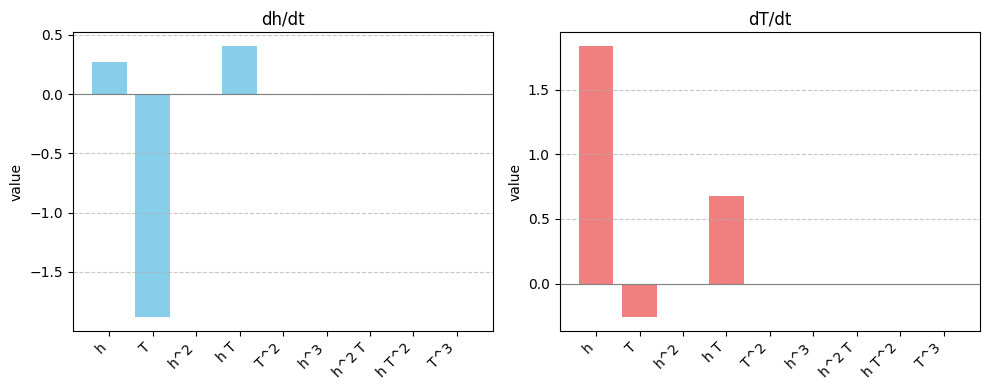

In [21]:
coefficients = model.coefficients()
feature_names_raw = model.get_feature_names()

# Replace 'x0' with 'h' and 'x1' with 'T' for readability in plots
plot_feature_names = [name.replace('x0', 'h').replace('x1', 'T') for name in feature_names_raw]

coeff_h = coefficients[0]
coeff_T = coefficients[1]

terms_to_plot = plot_feature_names
coeffs_h_plot = list(coeff_h)
coeffs_T_plot = list(coeff_T)

plt.figure(figsize=(10, 4))

# Plot for dh/dt
plt.subplot(1, 2, 1)
x_pos_h = np.arange(len(terms_to_plot))
plt.bar(x_pos_h, coeffs_h_plot, color='skyblue')
plt.xticks(x_pos_h, terms_to_plot, rotation=45, ha='right')
plt.ylabel('value')
plt.title('dh/dt')
plt.axhline(0, color='gray', linewidth=0.8)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot for dT/dt
plt.subplot(1, 2, 2)
x_pos_T = np.arange(len(terms_to_plot))
plt.bar(x_pos_T, coeffs_T_plot, color='lightcoral')
plt.xticks(x_pos_T, terms_to_plot, rotation=45, ha='right')
plt.ylabel('value')
plt.title('dT/dt')
plt.axhline(0, color='gray', linewidth=0.8)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

#SINDy Prediction for El-Nino events

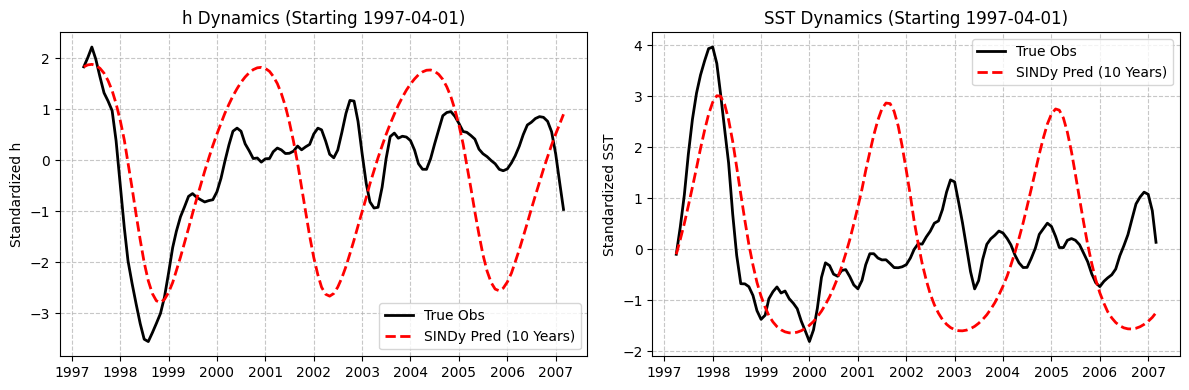

In [22]:
# ENSO event
start_date_str = '1997-04-01'
pred_duration_months = 12 * 10

start_date = pd.to_datetime(start_date_str)
mask_pred = (time_aligned >= start_date)
start_idx_pred = np.where(mask_pred)[0][0]

h_0 = h_standardized.iloc[start_idx_pred]
sst_0 = sst_standardized.iloc[start_idx_pred]
x0_pred = np.array([h_0, sst_0])

dt_pred = 1/12.0
t_pred = np.arange(pred_duration_months) * dt_pred

X_sim_pred = model.simulate(x0_pred, t=t_pred)

end_idx_pred = min(start_idx_pred + pred_duration_months, len(time_aligned))
actual_duration = end_idx_pred - start_idx_pred

h_true = h_standardized.iloc[start_idx_pred:end_idx_pred].to_numpy()
sst_true = sst_standardized.iloc[start_idx_pred:end_idx_pred].to_numpy()

time_plot_pred = [start_date + pd.DateOffset(months=i) for i in range(pred_duration_months)]
time_plot_true = time_plot_pred[:actual_duration]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
# h
axs[0].plot(time_plot_true, h_true, 'k-', linewidth=2, label='True Obs')
axs[0].plot(time_plot_pred, X_sim_pred[:, 0], 'r--', linewidth=2, label='SINDy Pred (10 Years)')
axs[0].set_title(f'h Dynamics (Starting {start_date_str})')
axs[0].set_ylabel('Standardized h')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.7)

# SST
axs[1].plot(time_plot_true, sst_true, 'k-', linewidth=2, label='True Obs')
axs[1].plot(time_plot_pred, X_sim_pred[:, 1], 'r--', linewidth=2, label='SINDy Pred (10 Years)')
axs[1].set_title(f'SST Dynamics (Starting {start_date_str})')
axs[1].set_ylabel('Standardized SST')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


#The Dynamical properties of the reconstructed system

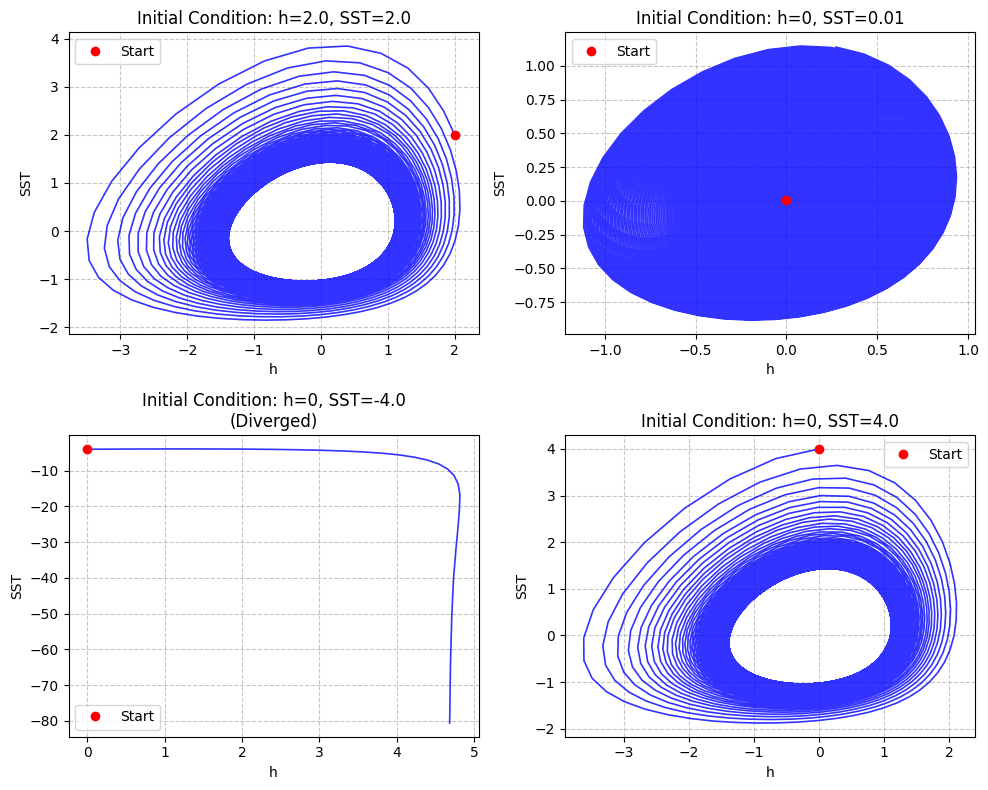

In [23]:
# Define different initial conditions [h, SST] to explore various behaviors
initial_conditions = [
    [2.0, 2.0],
    [0, 0.01],
    [0, -4.0],
    [0, 4.0]
]

# Time array for long-term integration (e.g., 50 years, dt=1/12)
t_long = np.arange(0, 1000, 1/12.0)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs = axs.flatten()

def rhs(t, x):
    return model.predict(x[np.newaxis, :])[0]

# Event function to stop integration if values get too large (divergence)
def diverge_event(t, x):
    return 100.0 - np.max(np.abs(x))  # Stop if any value exceeds 100
diverge_event.terminal = True

for i, x0 in enumerate(initial_conditions):
    # Simulate using solve_ivp directly to handle divergence gracefully
    res = solve_ivp(rhs, (t_long[0], t_long[-1]), x0, t_eval=t_long, events=diverge_event, method='RK45')
    X_sim_long = res.y.T

    # Plot phase trajectory (h vs SST)
    axs[i].plot(X_sim_long[:, 0], X_sim_long[:, 1], 'b-', linewidth=1.2, alpha=0.8)
    axs[i].plot(x0[0], x0[1], 'ro', markersize=6, label='Start') # Mark the starting point

    title_str = f'Initial Condition: h={x0[0]}, SST={x0[1]}'
    if res.status == 1:
        title_str += '\n(Diverged)'

    axs[i].set_title(title_str)
    axs[i].set_xlabel('h')
    axs[i].set_ylabel('SST')
    axs[i].grid(True, linestyle='--', alpha=0.7)
    axs[i].legend()

plt.tight_layout()
plt.show()


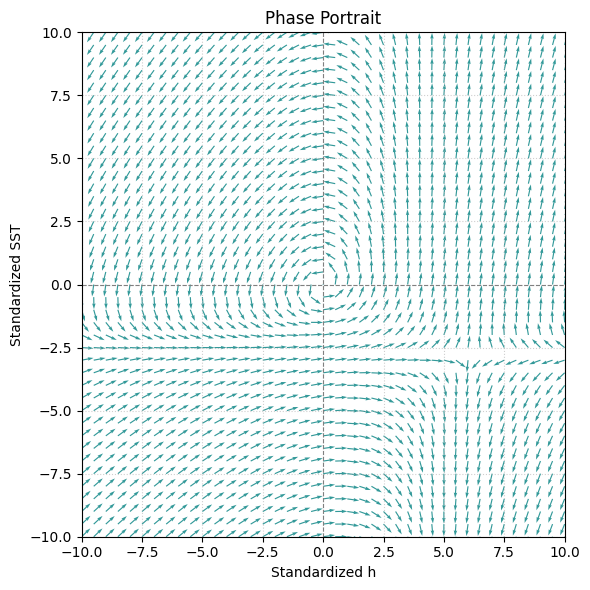

In [24]:
# Define the grid range for h and SST
h_vals = np.linspace(-10, 10, 41)
sst_vals = np.linspace(-10, 10, 41)
H, SST = np.meshgrid(h_vals, sst_vals)

grid_points = np.stack([H.flatten(), SST.flatten()], axis=-1)
derivatives = np.asarray(model.predict(grid_points))

# Reshape back to the grid shape
dH = derivatives[:, 0].reshape(H.shape)
dSST = derivatives[:, 1].reshape(SST.shape)

# Normalize the arrows for uniform length
magnitude = np.sqrt(dH**2 + dSST**2)
# Avoid division by zero
magnitude = np.where(magnitude == 0, 1, magnitude)
dH_norm = dH / magnitude
dSST_norm = dSST / magnitude

# Plot the vector field using quiver
plt.figure(figsize=(6, 6))
# Use the scale parameter to adjust arrow length (smaller scale = longer arrows)
plt.quiver(H, SST, dH_norm, dSST_norm, color='teal', alpha=0.8, angles='xy', scale=40)

plt.title('Phase Portrait')
plt.xlabel('Standardized h')
plt.ylabel('Standardized SST')
plt.xlim([-10, 10])
plt.ylim([-10, 10])
plt.axhline(0, color='gray', linewidth=0.8, linestyle='--')
plt.axvline(0, color='gray', linewidth=0.8, linestyle='--')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()





#The Stochastic System

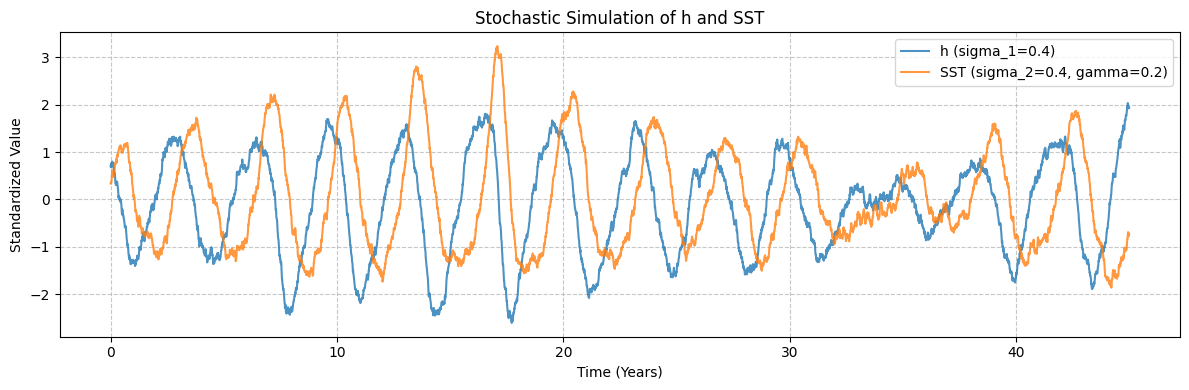

In [25]:
# Define simulation parameters
T_total = 45.0  # Total time for simulation (year)
dt = 1/12*0.1      # Time step
N_steps = int(T_total / dt)
t_stoch = np.linspace(0, T_total, N_steps)

# Define noise intensities and coupling
sigma_1 = 0.4 # Intensity of noise xi_1 for h
sigma_2 = 0.4  # Intensity of noise xi_2 for SST
gamma = 0.2    # Coupling coefficient of xi_1 into SST equation

# Initial condition: e.g., starting near a slight positive anomaly (mild El Nino build-up)
start_date_str = '1980-01-01'

start_date = pd.to_datetime(start_date_str)
mask_pred = (time_aligned >= start_date)
start_idx_pred = np.where(mask_pred)[0][0]

h_0 = h_standardized.iloc[start_idx_pred]
sst_0 = sst_standardized.iloc[start_idx_pred]
x0_stoch = np.array([h_0, sst_0])

# Arrays to store the trajectory
X_stoch = np.zeros((N_steps, 2))
X_stoch[0] = x0_stoch

# RK4 step for deterministic part
def rk4_step(model, x, dt):
    k1 = model.predict(x[np.newaxis, :])[0]
    k2 = model.predict((x + 0.5 * dt * k1)[np.newaxis, :])[0]
    k3 = model.predict((x + 0.5 * dt * k2)[np.newaxis, :])[0]
    k4 = model.predict((x + dt * k3)[np.newaxis, :])[0]
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

# Euler-Maruyama + RK4 integration
for i in range(1, N_steps):
    x_prev = X_stoch[i-1]

    # Deterministic part from SINDy model using RK4
    x_det = rk4_step(model, x_prev, dt)

    # Stochastic part (Wiener increments dW ~ N(0, dt))
    dW1 = np.random.normal(0, np.sqrt(dt))
    dW2 = np.random.normal(0, np.sqrt(dt))

    # Update state
    X_stoch[i, 0] = x_det[0] + sigma_1 * dW1
    X_stoch[i, 1] = x_det[1] + gamma * sigma_1 * dW1 + sigma_2 * dW2

# Plotting the stochastic trajectories
plt.figure(figsize=(12, 4))

# h and SST plots on the same axis
plt.plot(t_stoch, X_stoch[:, 0], linewidth=1.5, alpha=0.8, label=f'h (sigma_1={sigma_1})')
plt.plot(t_stoch, X_stoch[:, 1], linewidth=1.5, alpha=0.8, label=f'SST (sigma_2={sigma_2}, gamma={gamma})')

plt.title('Stochastic Simulation of h and SST')
plt.ylabel('Standardized Value')
plt.xlabel('Time (Years)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()


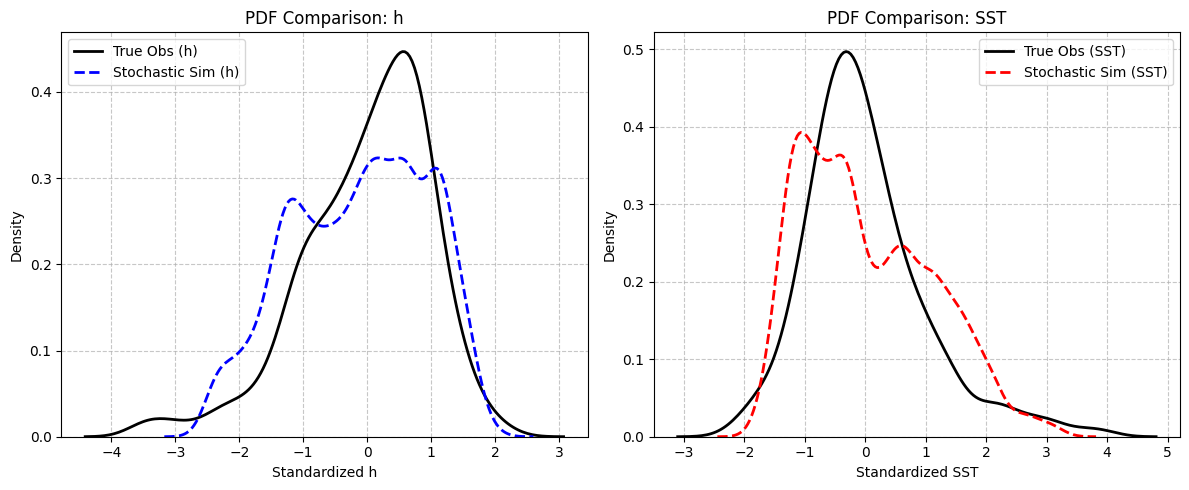

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# PDF comparison for h
sns.kdeplot(h_standardized.dropna(), ax=axs[0], color='black', label='True Obs (h)', linewidth=2)
sns.kdeplot(X_stoch[:, 0], ax=axs[0], color='blue', linestyle='--', label='Stochastic Sim (h)', linewidth=2)
axs[0].set_title('PDF Comparison: h')
axs[0].set_xlabel('Standardized h')
axs[0].set_ylabel('Density')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.7)

# PDF comparison for SST
sns.kdeplot(sst_standardized.dropna(), ax=axs[1], color='black', label='True Obs (SST)', linewidth=2)
sns.kdeplot(X_stoch[:, 1], ax=axs[1], color='red', linestyle='--', label='Stochastic Sim (SST)', linewidth=2)
axs[1].set_title('PDF Comparison: SST')
axs[1].set_xlabel('Standardized SST')
axs[1].set_ylabel('Density')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
